In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [2]:
def generate_random_gaussians_in_box_by_translation(N, sigma=2, n_gaussians=3):

    ### Need to fix many things about this function, just a quick hack for now

    f = np.zeros((N,N,N))
    z = utils.generate_centered_gaussian(N=N, d=3, sigma=sigma)

    for n in range(n_gaussians):
        tz, ty, tx = np.random.randint(-N//4, N//4 + 1, 3)
        f += transforms.translate_3d(z, tz, ty, tx)

    return f

In [3]:
# ##### TEST 1 - ROTATE POINTS

# ### select points on [-1,1]^3 , (x, y, z)


# p1 = np.array([0.3, 0, 0.3])
# p2 = np.array([-0.3, 0, 0.3])
# p3 = np.array([0, 0, 0])

### should try to match the voxel version below
p1 = np.array([0, -0.3, 0])
p2 = np.array([-0.4, 0, 0.5])
p3 = np.array([-0.3, 0.3, 0])
p4 = np.array([0, 0, 0])

p = np.array([p1, p2, p3, p4])


### or just pick randomly (using 0.5 because of spread from Gaussian)
# n_points = 10
# p = np.random.uniform(-0.5, 0.5, (n_points, 3))


### compute rotation matrix ZYZ (omega -> theta -> phi) and rotated points

omega = np.deg2rad(20)
theta = np.deg2rad(120)
phi = np.deg2rad(48)

# omega = np.deg2rad(np.random.randint(0, 360))
# theta = np.deg2rad(np.random.randint(0, 180))
# phi = np.deg2rad(np.random.randint(0, 360))

R = transforms.rotate_zyz(phi, theta, omega)

p_r = (R @ p.T).T # rotated points 

### create voxel array with points

N = 67

f = utils.generate_voxel_array_from_points(p, N)
g = utils.generate_voxel_array_from_points(p_r, N)

### convlove points with Gaussian

sigma = 2
z = utils.generate_centered_gaussian(d=3, sigma=sigma, N=N)

f = utils.signal_convolution(f, z)
g = utils.signal_convolution(g, z)

thetas = np.linspace(0, np.pi, N, endpoint=True)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)

f = signals.Signal(f, d=3).preprocess_signals()[0]
Pf = transforms.Transform(f, d=3).radon_transform()[0]

g = signals.Signal(g, d=3).preprocess_signals()[0]

In [4]:
# # ##### TEST 2 - ROTATE VOXEL ARRAY

# np.random.seed(0)

# N = 67
# sigma = 2

# z = utils.generate_centered_gaussian(N=N, d=3, sigma=sigma)
# f_1 = transforms.translate_3d(z, 0, 10, 0)     # move centered blob down
# f_2 = transforms.translate_3d(z, 0, -15, -20)  # move blob far left and up
# f_3 = transforms.translate_3d(z, 10, 0, 10)    # move blob back and right
# f = f_1 + f_2 + f_3 
# # f = transforms.translate_3d(f, 0, 10, 0)

# # f = generate_random_gaussians_in_box_by_translation(N=N, sigma=sigma, n_gaussians=10)

# f = signals.Signal(f, d=3).preprocess_signals()[0]
# Pf = transforms.Transform(f, d=3).radon_transform()[0]
# # Pf_bh = transforms.Transform(f, d=3).ball_harmonic_projections()

# thetas = np.linspace(0, np.pi, N, endpoint=True)
# phis = np.linspace(0, 2*np.pi, N, endpoint=False)

# # omega = np.deg2rad(0)
# # theta = np.deg2rad(157)
# # phi = np.deg2rad(53)


# omega = np.deg2rad(np.random.randint(0,360))
# theta = np.deg2rad(np.random.randint(0,180))
# phi = np.deg2rad(np.random.randint(0,360))

# g = transforms.rotate_voxel_zyz(f, omega, theta, phi)
# g = signals.Signal(g, d=3).preprocess_signals()[0]

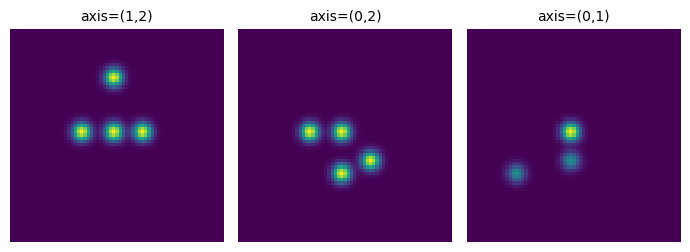

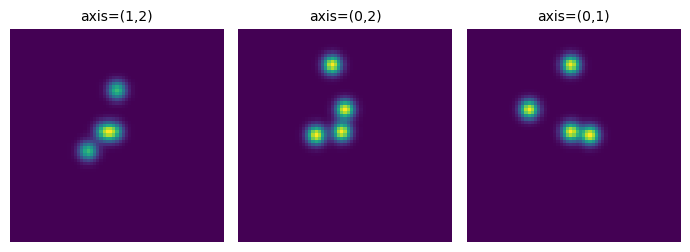

In [5]:
plots.orthogonal_2D_projection_plot(f)
plots.orthogonal_2D_projection_plot(g)

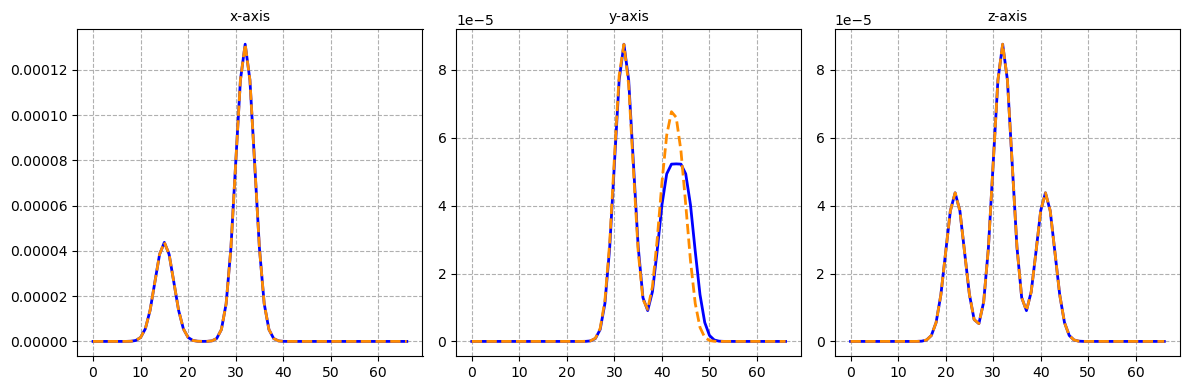

In [6]:
plots.orthogonal_1D_projection_comparison_plot(f * ((2 - 2/N)**2) / (N**2), Pf)
# plots.orthogonal_1D_projection_comparison_plot(f * ((2 - 2/N)**2) / (N**2), Pf_bh)

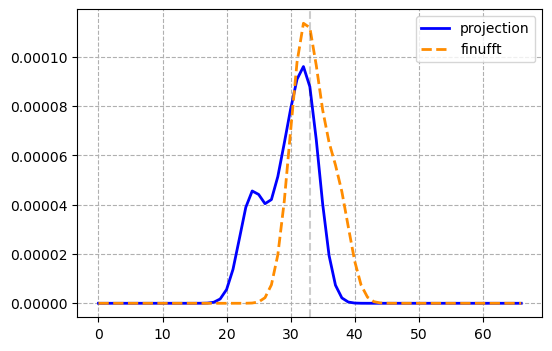

In [7]:
phi_idx = np.argmin(abs(phis - abs(phi)))
theta_idx = np.argmin(abs(thetas - abs(theta)))

plt.figure(figsize=(6,4))

### based on our notation, we define Pf[0, :, 0] as the z-axis projection
### this corresponds to np.sum(g, axis=(0,1)) (I would have guessed axis=(0,2))
plt.plot(np.sum(g * ((2 - 2/N)**2) / (N**2), axis=(0,1)), linewidth=2, color='blue', label='projection')

plt.plot(Pf[phi_idx, :, theta_idx], linewidth=2, linestyle='--', color='darkorange', label='finufft')

plt.axvline(N//2, linestyle='--', color='k', alpha=0.2)
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

In [8]:
print(' theta gt: ', np.rad2deg(theta))
print('theta idx: ', np.rad2deg(thetas)[theta_idx])
print('   phi gt: ', np.rad2deg(phi))
print('  phi idx: ', np.rad2deg(phis)[phi_idx])

 theta gt:  119.99999999999999
theta idx:  119.99999999999999
   phi gt:  48.00000000000001
  phi idx:  48.35820895522388
